In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scrublet as scr
import session_info

/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Impor

In [2]:
import session_info
session_info.show()

In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=100, facecolor='white', color_map = 'RdPu',)

In [4]:
adata_endo2=sc.read_h5ad(
    '/path/to/h5ad_subcluster/07_tcell_harmony_bbk.h5ad')

# Annotation

In [5]:
res=6.0 
sc.tl.leiden(adata_endo2,resolution=res,
             key_added=f'res_{res}',
             flavor='igraph',
             n_iterations=2)

running Leiden clustering
    finished: found 73 clusters and added
    'res_6.0', the cluster labels (adata.obs, categorical) (0:01:30)


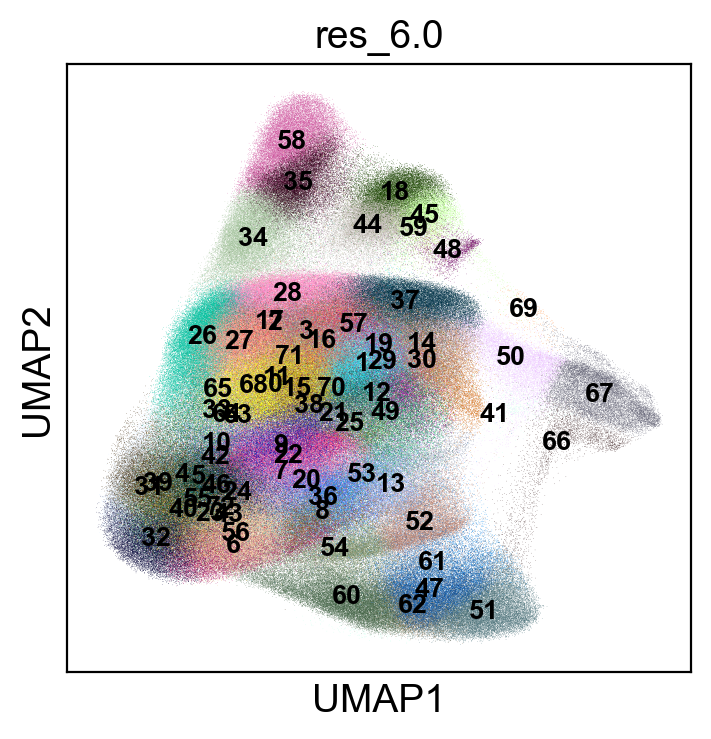

In [6]:
sc.pl.umap(adata_endo2,
           color=f'res_{res}',
           legend_loc='on data',legend_fontsize='x-small',
          )

# celltypist result

In [7]:
adata=sc.read_h5ad('/path/to/h5ad_subcluster/07_tcell_harmony_bbk_celltypist.h5ad')

In [8]:
adata_endo2.obs['sub_anno_before']=adata.obs['majority_voting'].copy()

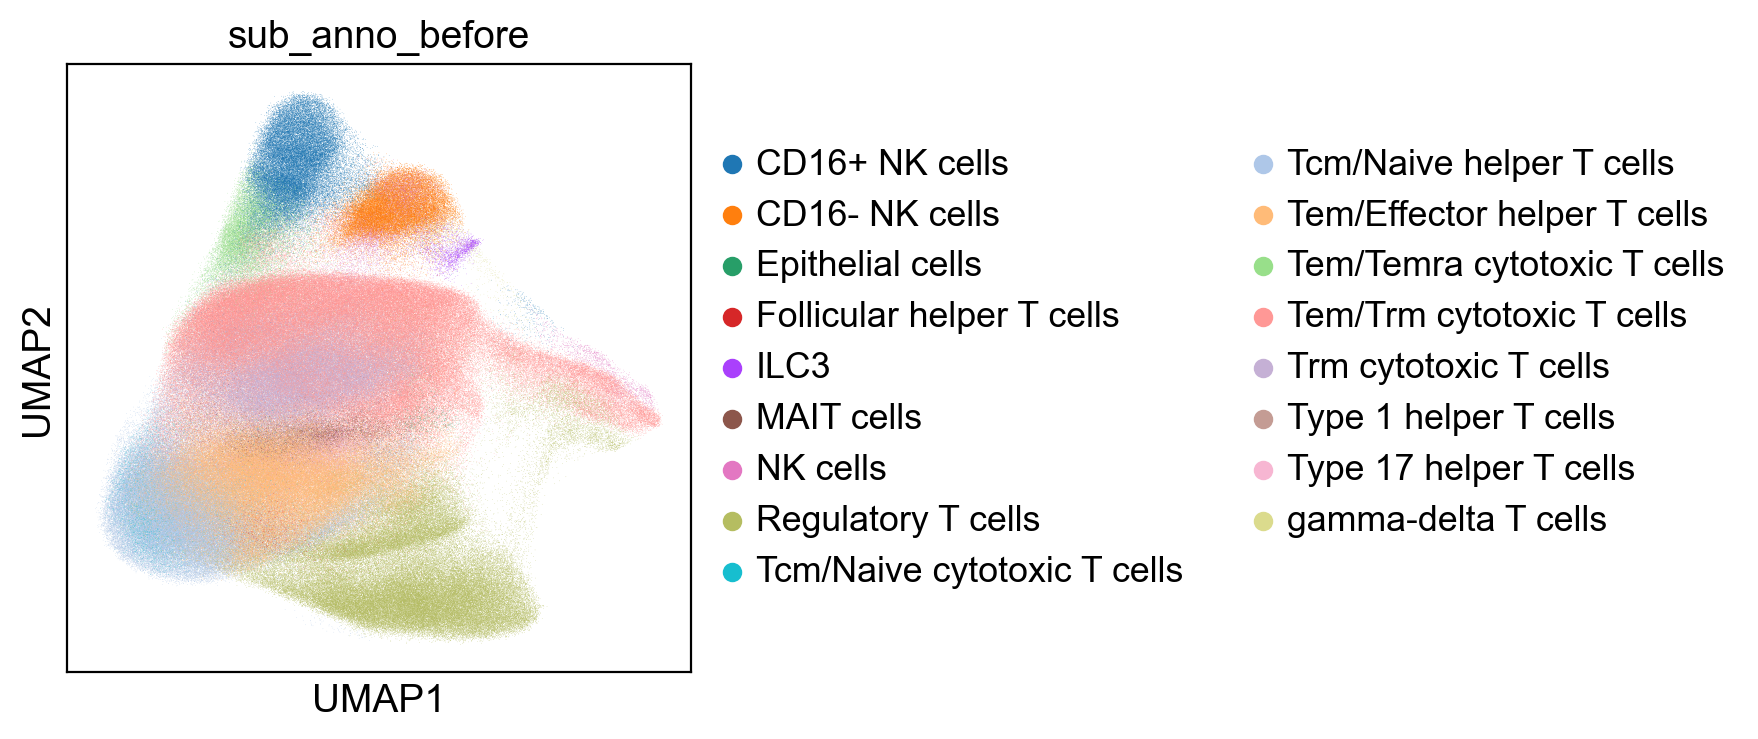

In [9]:
sc.pl.umap(adata_endo2,color='sub_anno_before')

# Marker expression

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_res_6.0']`
categories: 0, 1, 2, etc.
var_group_labels: CD4/CD8, naive/cm T, CD8+ Interferon, etc.


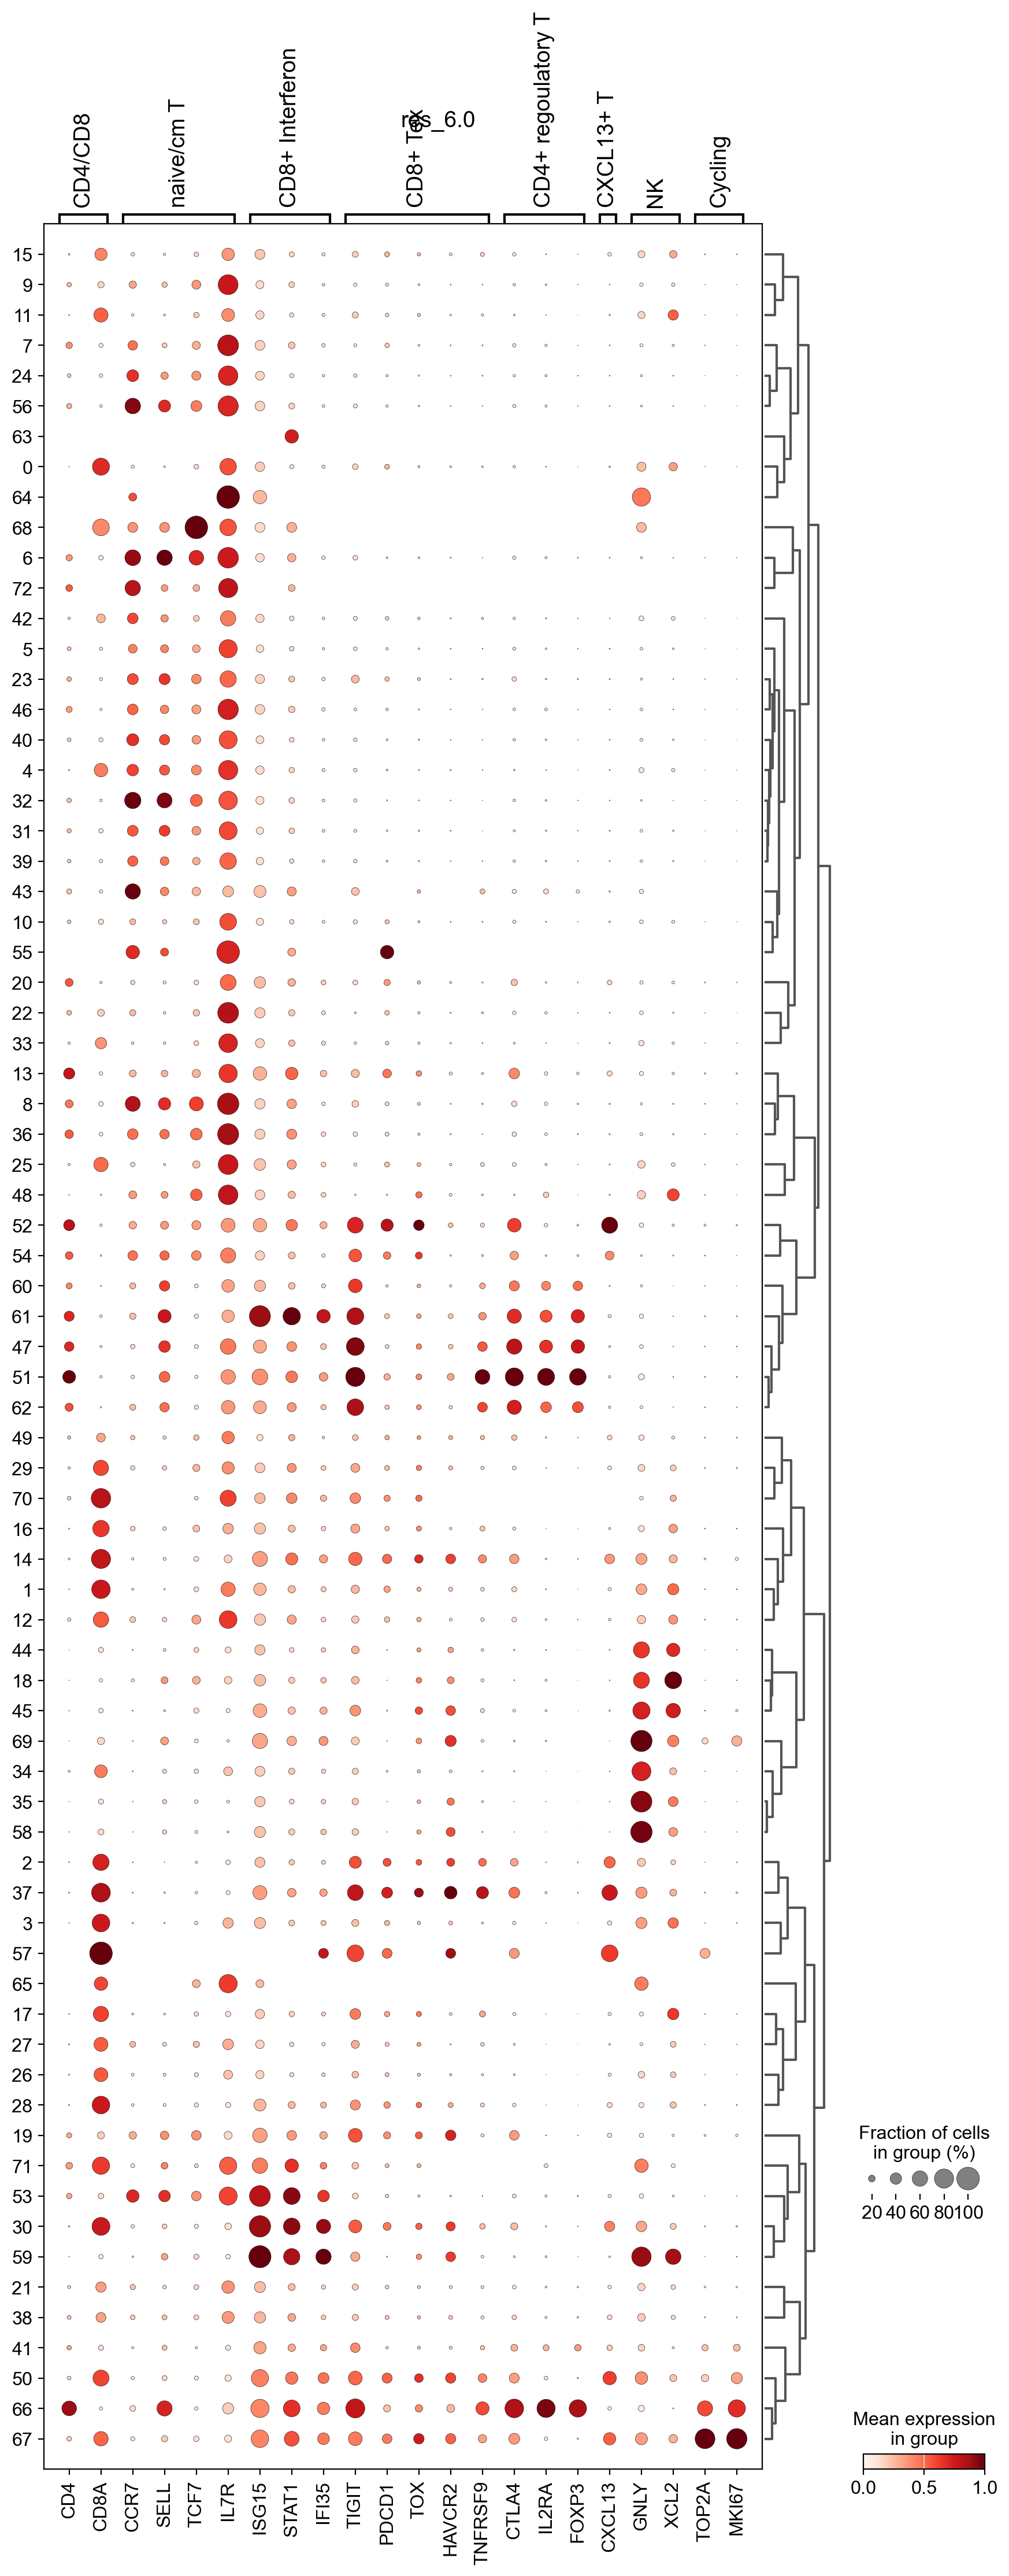

In [10]:
markers={'CD4/CD8':['CD4','CD8A'],
         'naive/cm T':['CCR7', 'SELL', 'TCF7', 'IL7R'], 
         "CD8+ Interferon": ["ISG15", "STAT1", "IFI35"],
         'CD8+ Tex' :[ "TIGIT", "PDCD1", "TOX", "HAVCR2",'TNFRSF9'],
         'CD4+ regoulatory T' :['CTLA4','IL2RA','FOXP3'],
         'CXCL13+ T':['CXCL13'],
         'NK' :['GNLY','XCL2'],
        'Cycling':['TOP2A','MKI67']}

sc.pl.dotplot(adata_endo2,groupby='res_6.0',
              title='res_6.0',dendrogram=True,standard_scale='var',
             var_names=markers)

In [11]:
# majority_voting을 복사한 뒤 str로 변환 (categorical 제약에서 벗어남 → add_categories 불필요)
sub = adata.obs['majority_voting'].astype(str).copy()

# 라벨 ← 클러스터(res_6.0) 매핑
label_to_clusters = {
    'CD8 Tex':          ['37'],
    'CD8 Cycling Tex':  ['50', '57', '67'],
    'CD8 ISG15+ T':     ['30'],
    'CD4 Cycling Treg': ['66'],
    'CD4 Treg':         ['60', '61', '62', '47', '51'],
    'CD4 CXCL13+ T':    ['54', '52'],
}

for label, clusters in label_to_clusters.items():
    sub[adata_endo2.obs['res_6.0'].isin(clusters)] = label

# 작업이 끝나면 categorical로 변환해서 저장
adata_endo2.obs['sub_anno_before'] = pd.Categorical(sub)

In [12]:
mapping = {
    'CD8 Tex':'CD8 Tex',
    'CD4 Treg':'CD4 Treg',
    'CD8 Cycling Tex':'CD8 Cycling Tex',
    'CD4 Cycling Treg':'CD4 Cycling Treg',
    'CD8 ISG15+ T':'CD8 ISG15+ T',
    'CD4 CXCL13+ T':'CD4 CXCL13+ T',
    'CD16+ NK cells': 'CD16+ NK',
    'CD16- NK cells': 'CD16- NK',
    'Follicular helper T cells': 'CD4 Tfh',
    'ILC3': 'ILC3',
    'MAIT cells': 'MAIT',
    'NK cells': 'NK',
    'Regulatory T cells': 'CD4 Unassigned T',
    'Tcm/Naive cytotoxic T cells': 'CD8 Tcm/Tn',
    'Tcm/Naive helper T cells': 'CD4 Tcm/Tn',
    'Tem/Effector helper T cells': 'CD4 Tem/Effector',
    'Tem/Temra cytotoxic T cells': 'CD8 Tem/Temra',
    'Tem/Trm cytotoxic T cells': 'CD8 Tem/Trm',
    'Trm cytotoxic T cells': 'CD8 Trm',
    'Type 1 helper T cells': 'CD4 Th1',
    'Type 17 helper T cells': 'CD4 Th17',
    'gamma-delta T cells': 'γδ T',
    'Epithelial cells': 'Doublet'}

# mapping
adata_endo2.obs['sub_anno'] = (
    adata_endo2.obs['sub_anno_before'].astype(str).str.strip().map(mapping)
)

In [13]:
adata_endo2.obs['sub_anno'].isna().sum()

0

In [14]:
len(adata_endo2.obs['sub_anno'].value_counts())

23

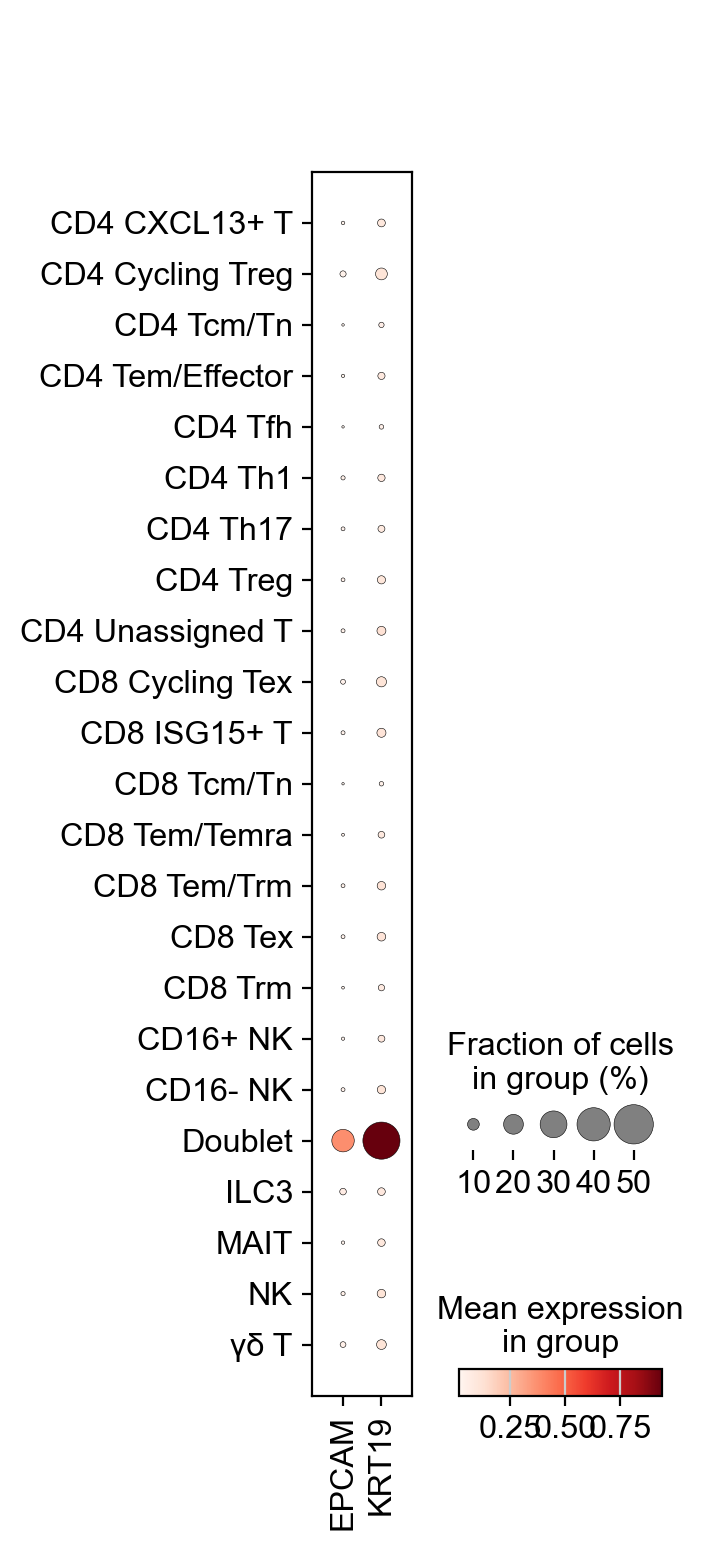

In [15]:
sc.pl.dotplot(adata_endo2, groupby='sub_anno',var_names=['EPCAM','KRT19'])

In [16]:
adata_endo3=adata_endo2[~adata_endo2.obs['sub_anno'].isin(['Doublet'])]
len(adata_endo3.obs['sub_anno'].value_counts())

22

In [17]:
sc.tl.rank_genes_groups(adata_endo3,groupby='sub_anno',method='wilcoxon')

ranking genes


/home/Data_Drive_8TB/ahwodn/.conda/envs/pan_vis/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:645: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}


    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:27:17)


/home/Data_Drive_8TB/ahwodn/.conda/envs/pan_vis/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:435: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/home/Data_Drive_8TB/ahwodn/.conda/envs/pan_vis/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:437: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/home/Data_Drive_8TB/ahwodn/.conda/envs/pan_vis/lib/python3.10/site-packages/scanpy/t

In [18]:
## celltype별 색상 할당
from matplotlib.colors import to_hex

# sub_anno가 categorical이 아니면 먼저 순서 지정
desired_order = [
    "CD8 Tcm/Tn",
    "CD8 Tem/Trm",
    "CD8 Tem/Temra",
    "CD8 Trm",
    "CD8 Tex",
    "CD8 Cycling Tex",
    "CD8 ISG15+ T",
    "CD4 Tcm/Tn",
    "CD4 Tem/Effector",
    "CD4 Th1",
    "CD4 Th17",
    "CD4 Tfh",
    "CD4 Treg",
    "CD4 Cycling Treg",
    "CD4 CXCL13+ T",
    "CD4 Unassigned T",
    "NK",
    "CD16+ NK",
    "CD16- NK",
    "γδ T",
    "MAIT",
    "ILC3",
]

adata_endo3.obs["sub_anno"] = adata_endo3.obs["sub_anno"].astype("category")
adata_endo3.obs["sub_anno"] = adata_endo3.obs["sub_anno"].cat.set_categories(desired_order, ordered=True)

cats = list(adata_endo3.obs["sub_anno"].cat.categories)

# 그룹별 카테고리 분류
cd8_cats = [x for x in cats if x.startswith("CD8")]
cd4_cats = [x for x in cats if x.startswith("CD4")]
nk_cats  = [x for x in cats if "NK" in x]
etc_cats = [x for x in cats if x not in cd8_cats + cd4_cats + nk_cats]

def make_colors(cmap_name, n, start=0.35, end=0.9):
    if n == 0:
        return []
    cmap = plt.get_cmap(cmap_name)
    vals = np.linspace(start, end, n)
    return [to_hex(cmap(v)) for v in vals]

# 색상 생성
cd8_colors = make_colors("Reds", n=len(cd8_cats))
cd4_colors = make_colors("Blues", n=len(cd4_cats))
nk_colors  = make_colors("Greens", n=len(nk_cats))
etc_colors = make_colors("Purples", n=len(etc_cats))

# 카테고리별 색 매핑
color_map = {}
color_map.update(dict(zip(cd8_cats, cd8_colors)))
color_map.update(dict(zip(cd4_cats, cd4_colors)))
color_map.update(dict(zip(nk_cats, nk_colors)))
color_map.update(dict(zip(etc_cats, etc_colors)))

# scanpy용 색 리스트 저장: 카테고리 순서와 정확히 맞춰야 함
adata_endo3.uns["sub_anno_colors"] = [color_map[x] for x in cats]

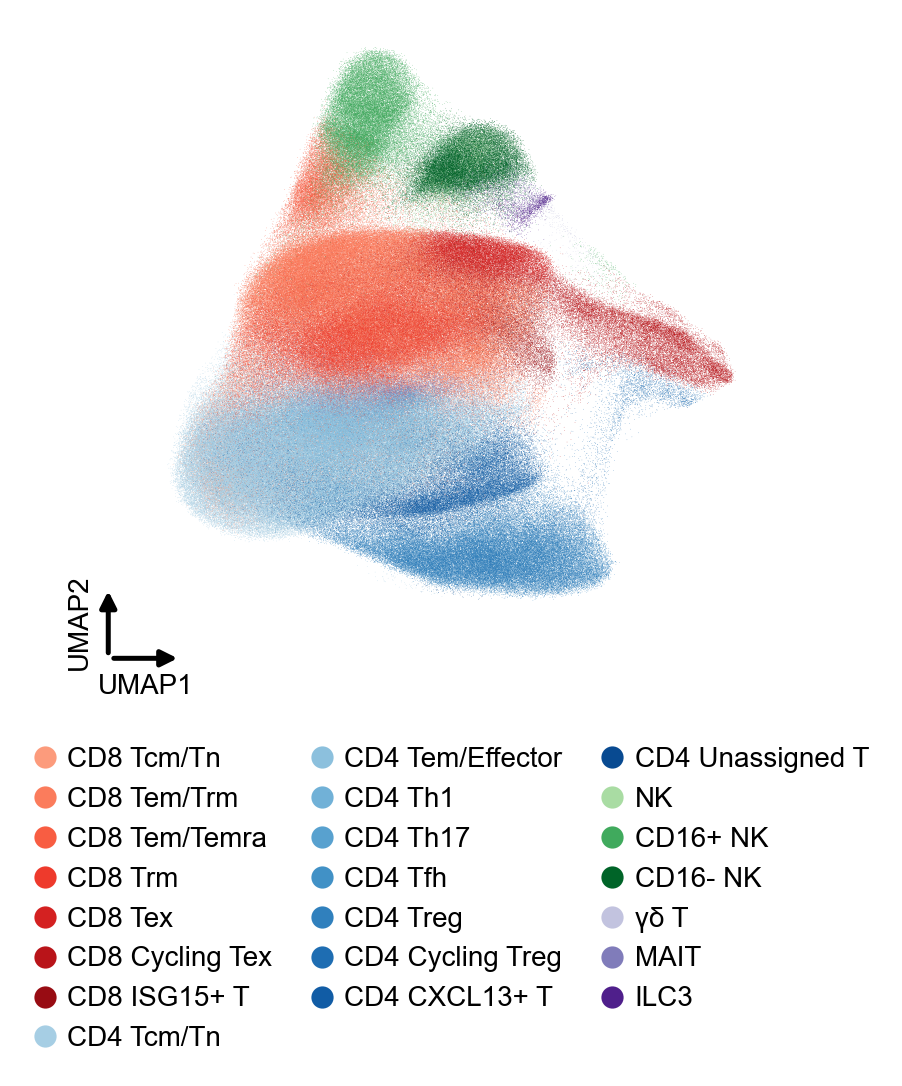

In [19]:
from plotting import umap_with_arrow_axes

umap_with_arrow_axes(adata_endo3)

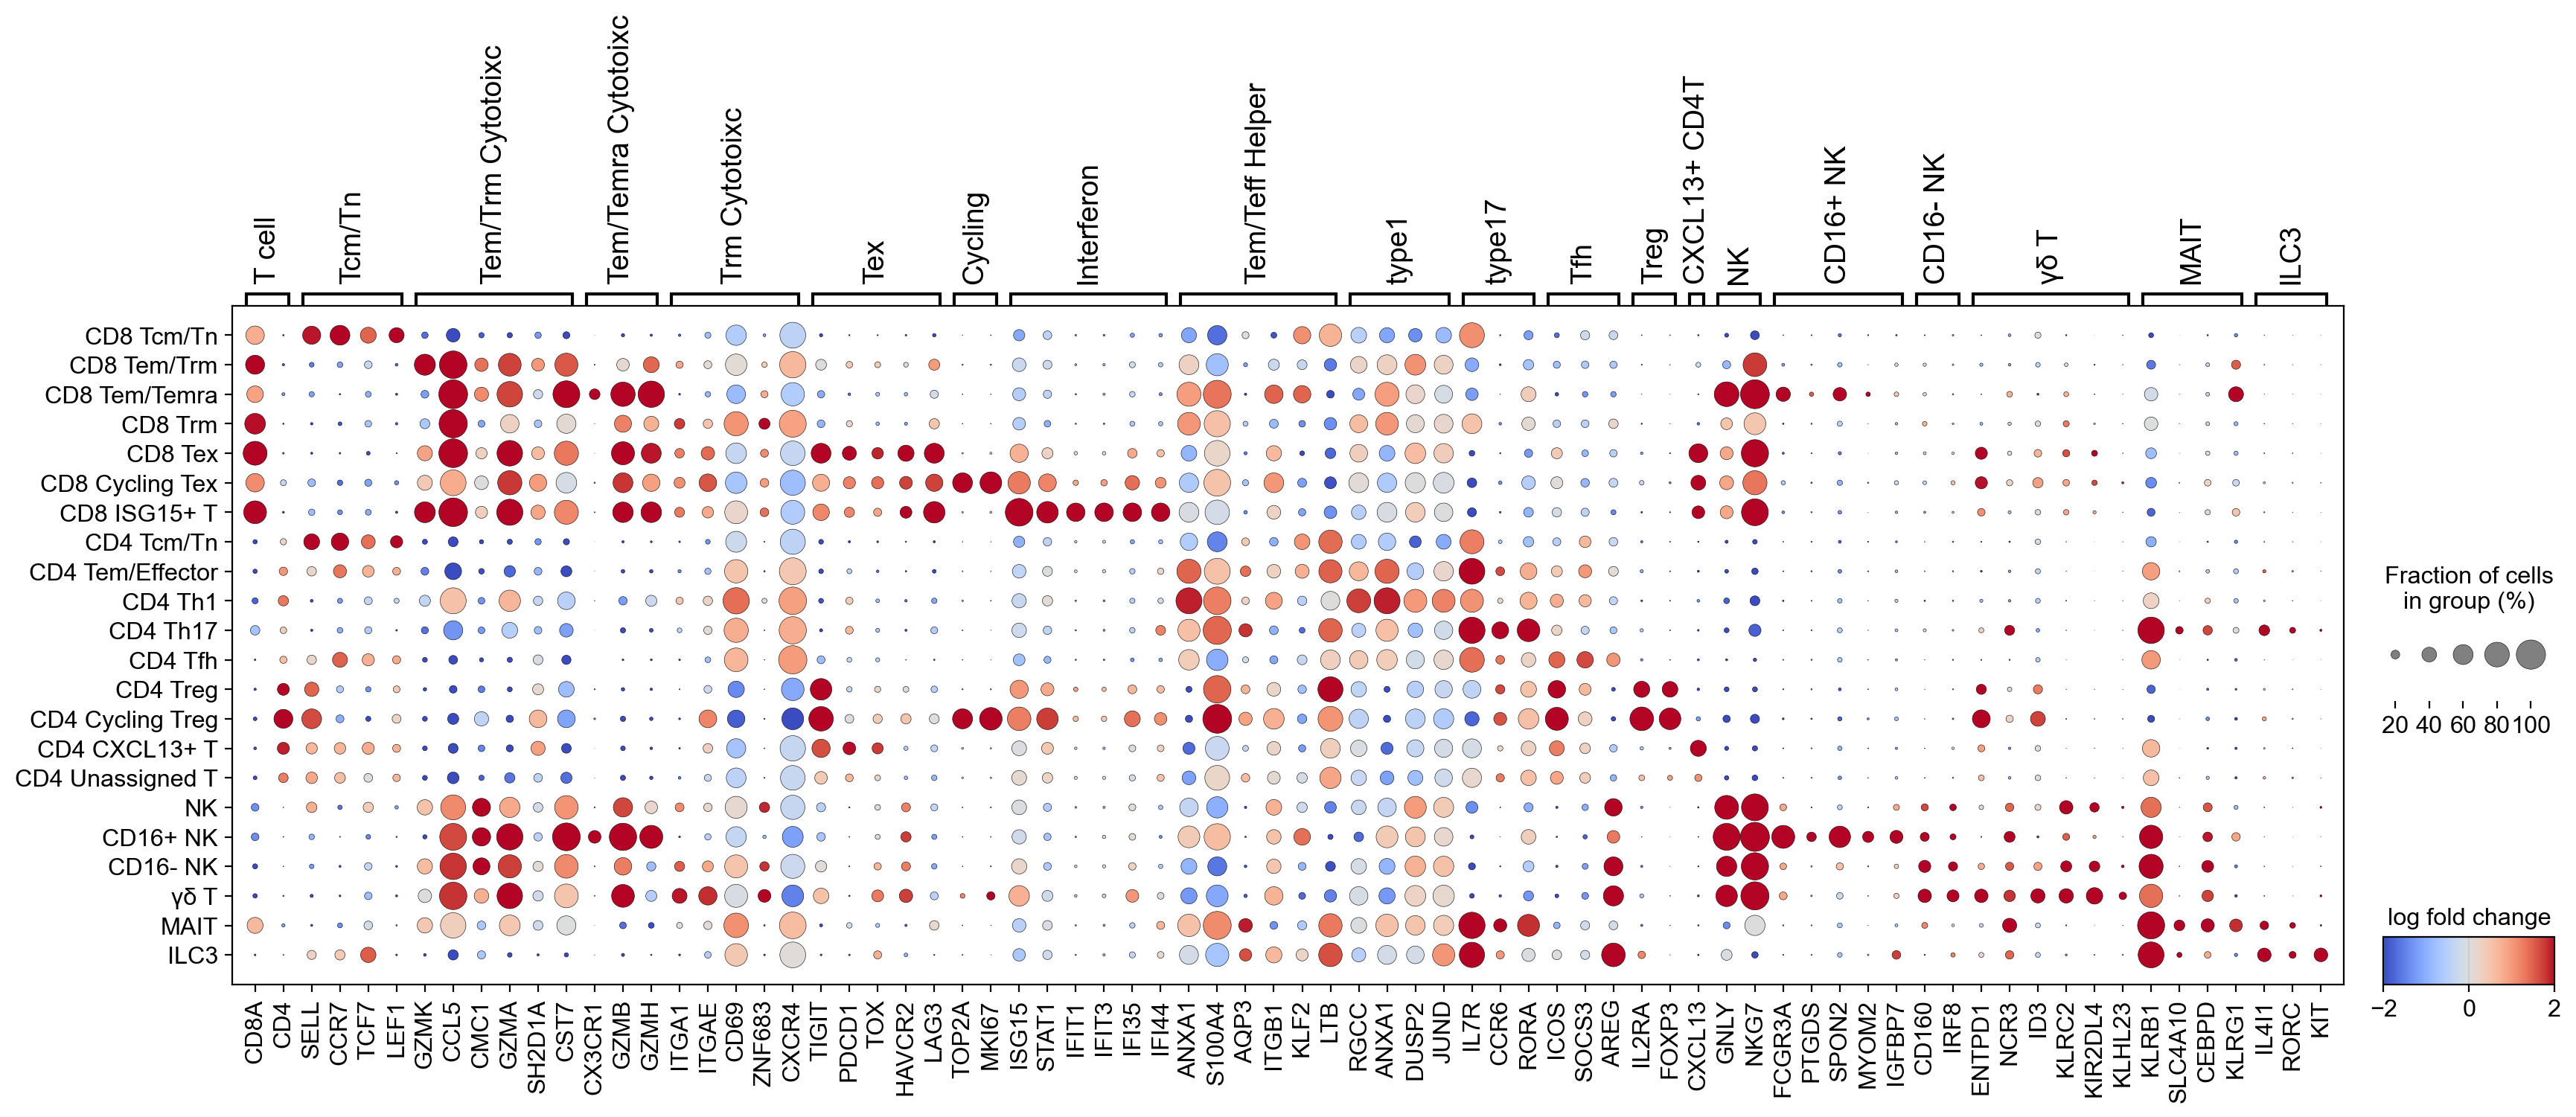

In [20]:
marker = {
    "T cell": ["CD8A", "CD4"],
    "Tcm/Tn": ["SELL", "CCR7", "TCF7", "LEF1"],
    "Tem/Trm Cytotoixc": ["GZMK", "CCL5", "CMC1", "GZMA", "SH2D1A", "CST7"],
    "Tem/Temra Cytotoixc": ["CX3CR1", "GZMB", "GZMH"],
    "Trm Cytotoixc": ["ITGA1", "ITGAE", "CD69", "ZNF683", "CXCR4"],
    "Tex": ["TIGIT", "PDCD1", "TOX", "HAVCR2", "LAG3"],
    "Cycling": ["TOP2A", "MKI67"],
    "Interferon": ["ISG15", "STAT1", "IFIT1", "IFIT3", "IFI35", "IFI44"],
    "Tem/Teff Helper": ["ANXA1", "S100A4", "AQP3", "ITGB1", "KLF2", "LTB",'CD69'],
    "type1": ["RGCC", "ANXA1", "DUSP2", "JUND"],
    "type17": ["IL7R", "CCR6", "RORA"],
    "Tfh": ["ICOS", "SOCS3", "AREG"],
    "Treg": ["IL2RA", "FOXP3"],
    "CXCL13+ CD4T": ["CXCL13"],
    "NK": ["GNLY", "NKG7","KLRD1"],
    "CD16+ NK": ["FCGR3A", "PTGDS", "SPON2", "MYOM2", "IGFBP7"],
    "CD16- NK": ['KLRC1',"CD160", "IRF8",],
    "γδ T": ["ENTPD1", "NCR3", "ID3", "KLRC2", "KIR2DL4", "KLHL23"],
    "MAIT": ["KLRB1", "SLC4A10", "CEBPD", "KLRG1"],
    "ILC3": ["IL4I1", "RORC", "KIT"],
}


sc.pl.rank_genes_groups_dotplot(
    adata_endo3,
    groupby="sub_anno",
    categories_order=cats,
    var_names=marker,
    key="rank_genes_groups",
    cmap="coolwarm",
    dendrogram=False,
    values_to_plot="logfoldchanges",
    vmax=2,
    vmin=-2,
    figsize=(20, 6),
)

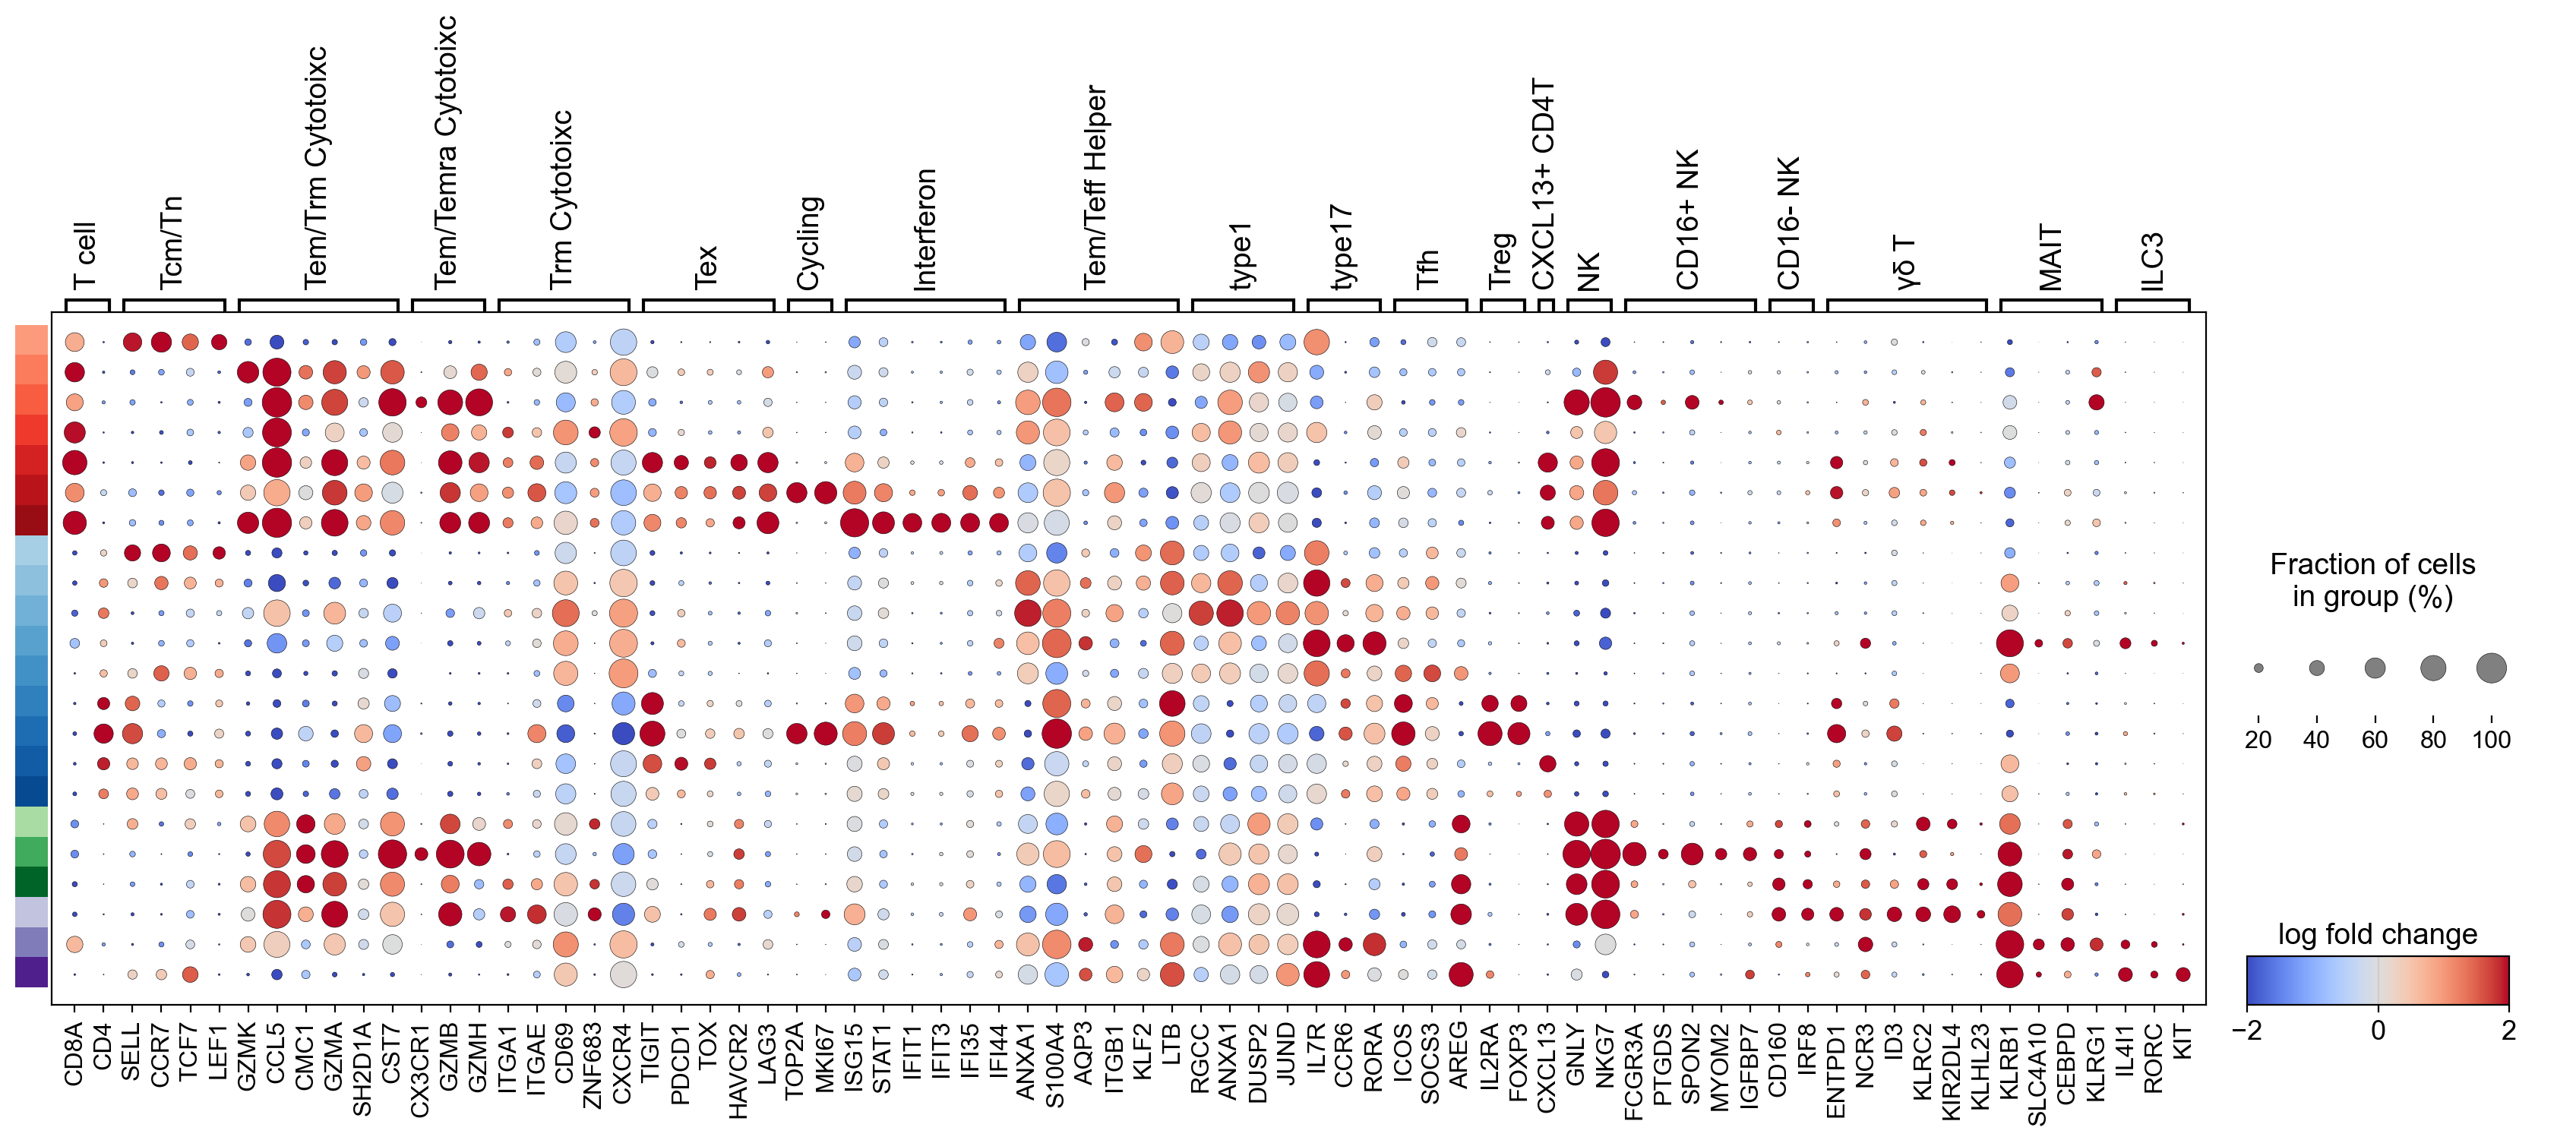

In [21]:
cats = list(adata_endo3.obs["sub_anno"].cat.categories)

dp = sc.pl.rank_genes_groups_dotplot(
    adata_endo3,
    groupby="sub_anno",
    categories_order=cats,
    var_names=marker,
    key="rank_genes_groups",
    cmap="coolwarm",
    dendrogram=False,
    values_to_plot="logfoldchanges",
    vmax=2,
    vmin=-2,
    figsize=(20, 6),
    return_fig=True,
    show=False,
)

axes = dp.get_axes()
ax = axes["mainplot_ax"]
fig = ax.figure

# row annotation color bar
color_map = dict(zip(cats, adata_endo3.uns["sub_anno_colors"]))
row_colors = [color_map[c] for c in cats]
rgb = np.array([mcolors.to_rgb(c) for c in row_colors]).reshape(len(cats), 1, 3)

ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)

pos = ax.get_position()
bar_ax = fig.add_axes([pos.x0 - 0.012, pos.y0 - 0.014, 0.0105, pos.height])

# 각 block의 중심을 dot row 중심과 맞춤
bar_ax.imshow(
    rgb,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    extent=(0, 1, -0.5, len(cats) - 0.5),
)

bar_ax.set_ylim(ax.get_ylim())
bar_ax.set_xlim(0, 1)
bar_ax.set_xticks([])
bar_ax.set_yticks([])

for spine in bar_ax.spines.values():
    spine.set_visible(False)

# dot size legend 조정
size_ax = axes["size_legend_ax"]
pos2 = size_ax.get_position()
size_ax.set_position([pos2.x0, pos2.y0, pos2.width * 1.8, pos2.height])
size_ax.set_title("Fraction of cells\nin group (%)", x=0.4, y=0.6)

coll = size_ax.collections[0]
offsets = coll.get_offsets()

new_x = np.array([0, 0.5, 1.0, 1.5, 2.0])[:offsets.shape[0]]
offsets[:, 0] = new_x
coll.set_offsets(offsets)

ticklabels = [t.get_text() for t in size_ax.get_xticklabels()]
size_ax.set_xticks(new_x)
size_ax.set_xticklabels(ticklabels)
size_ax.set_xlim(new_x.min() - 0.1, new_x.max() + 0.6)

# colorbar 조정
color_ax = axes["color_legend_ax"]
color_ax.set_title("log fold change", fontsize=14)
color_ax.tick_params(labelsize=13)

pos3 = color_ax.get_position()
color_ax.set_position([pos3.x0, pos3.y0, pos3.width * 1.5, pos3.height])

plt.show()

In [ ]:
del adata_endo3.obs['sub_anno_before']
adata_endo3.write_h5ad('/path/to/h5ad_annotated/_sc_Tcell.h5ad')